In [ ]:
pip install statsmodels pmdarima

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("../data/processed/RELIANCE_processed.csv", parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)
series = df.set_index("Date")["Close"]

# Lock in a business-day frequency up front so it survives slicing later
series = series.asfreq("B").ffill()

In [4]:
from statsmodels.tsa.stattools import adfuller

def adf_report(x, name):
    res = adfuller(x.dropna())
    print(f"{name}: ADF Stat = {res[0]:.4f}, p-value = {res[1]:.4f}")
    print("Stationary" if res[1] < 0.05 else "Non-stationary")

In [5]:
adf_report(series, "Close")

Close: ADF Stat = -1.2455, p-value = 0.6537
Non-stationary


In [6]:
adf_report(series.diff(), "Close diff 1")

Close diff 1: ADF Stat = -55.5094, p-value = 0.0000
Stationary


In [7]:
adf_report(series.pct_change(), "Returns")

Returns: ADF Stat = -23.4913, p-value = 0.0000
Stationary


In [8]:
split = int(len(series) * 0.8)

# asfreq on each slice keeps .freq intact (iloc can silently drop it)
train = series.iloc[:split].asfreq("B")
test  = series.iloc[split:].asfreq("B")

assert train.index.freq is not None, "train lost its frequency!"
assert test.index.freq  is not None, "test lost its frequency!"

print(f"Train: {train.index.min().date()} → {train.index.max().date()}  ({len(train)} rows)")
print(f"Test : {test.index.min().date()} → {test.index.max().date()}  ({len(test)} rows)")
print(f"Frequency: {train.index.freq}")

Train: 2015-01-30 → 2024-06-05  (2439 rows)
Test : 2024-06-06 → 2026-10-07  (610 rows)
Frequency: <BusinessDay>


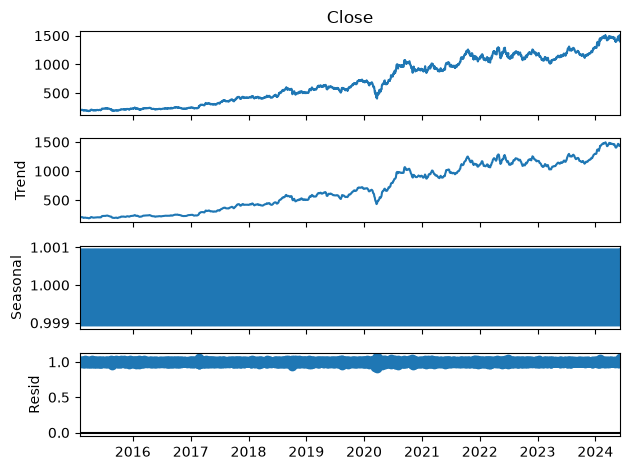

In [9]:
from statsmodels.tsa.seasonal import seasonal_decompose

dec = seasonal_decompose(train, model="multiplicative", period=5)
dec.plot(); plt.show()

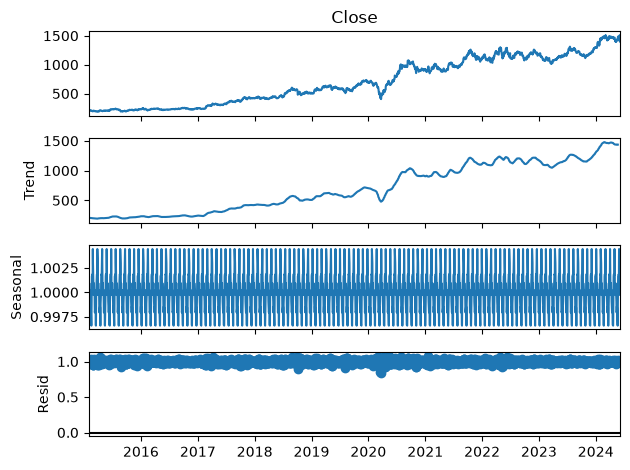

In [10]:
dec21 = seasonal_decompose(train, model="multiplicative", period=21)
dec21.plot(); plt.show()

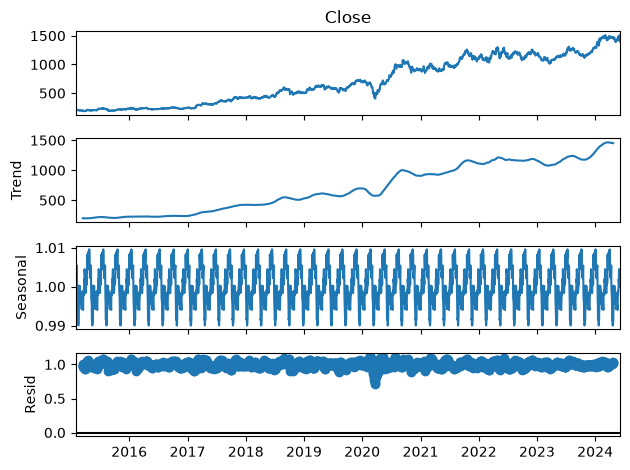

In [11]:
dec63 = seasonal_decompose(train, model="multiplicative", period=63)
dec63.plot(); plt.show()

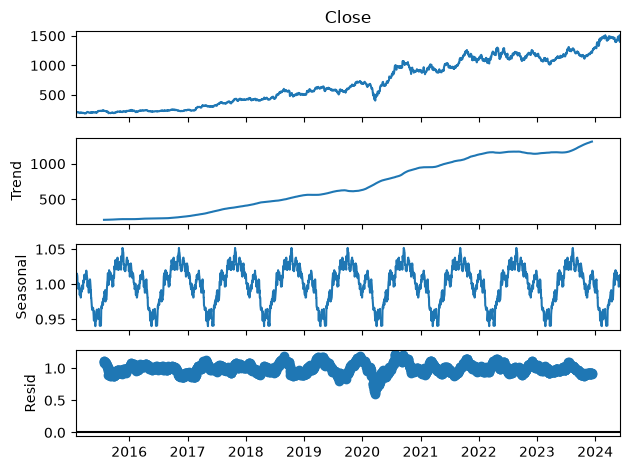

In [12]:
dec252 = seasonal_decompose(train, model="multiplicative", period=252)
dec252.plot(); plt.show()

In [13]:
import pmdarima as pm

In [14]:
auto_model = pm.auto_arima(
    train,
    start_p=0, max_p=5,
    start_q=0, max_q=5,
    d=None,
    seasonal=False,
    stepwise=True,
    suppress_warnings=True,
    trace=True,
    error_action="ignore",
    n_jobs=1
)

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=19389.395, Time=0.37 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=19390.251, Time=0.34 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=19390.273, Time=0.70 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=19391.014, Time=0.42 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=19392.768, Time=0.83 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0] intercept
Total fit time: 2.822 seconds


In [15]:
print("\n" + "="*60)
print("BEST MODEL:", auto_model.order)
print("AIC:", auto_model.aic())
print("="*60)
print(auto_model.summary())


BEST MODEL: (0, 1, 0)
AIC: 19389.395131723046
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2439
Model:               SARIMAX(0, 1, 0)   Log Likelihood               -9692.698
Date:                Thu, 15 Oct 2026   AIC                          19389.395
Time:                        21:00:31   BIC                          19400.993
Sample:                    01-30-2015   HQIC                         19393.611
                         - 06-05-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.4969      0.261      1.903      0.057      -0.015       1.009
sigma2       166.2470      2.008     82.807      0.000     162.312     170.182
Ljung

In [16]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

p, d, q = auto_model.order

model = SARIMAX(
    train,
    order=(p, d, q),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False,
    freq="B",              # <-- suppresses the ValueWarning, gives future B-days
)
result = model.fit(disp=False)
print(result.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 2439
Model:               SARIMAX(0, 1, 0)   Log Likelihood               -9691.022
Date:                Thu, 15 Oct 2026   AIC                          19384.045
Time:                        21:00:48   BIC                          19389.843
Sample:                    01-30-2015   HQIC                         19386.153
                         - 06-05-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2       166.5625      2.014     82.684      0.000     162.614     170.511
Ljung-Box (L1) (Q):                   1.14   Jarque-Bera (JB):              8680.71
Prob(Q):                              0.29   Pr

In [17]:
n_periods = len(test)

forecast_obj = result.get_forecast(steps=n_periods)
forecast = forecast_obj.predicted_mean          # already indexed on future B-days
conf_int = forecast_obj.conf_int(alpha=0.05)

# Sanity check: forecast dates must line up with test dates
assert forecast.index.equals(test.index), "Forecast index doesn't match test index!"

print(forecast.head())
print(conf_int.head())

2024-06-06    1420.75
2024-06-07    1420.75
2024-06-10    1420.75
2024-06-11    1420.75
2024-06-12    1420.75
Freq: B, Name: predicted_mean, dtype: float64
            lower Close  upper Close
2024-06-06  1395.454880  1446.045120
2024-06-07  1384.977299  1456.522701
2024-06-10  1376.937568  1464.562432
2024-06-11  1370.159761  1471.340239
2024-06-12  1364.188393  1477.311607


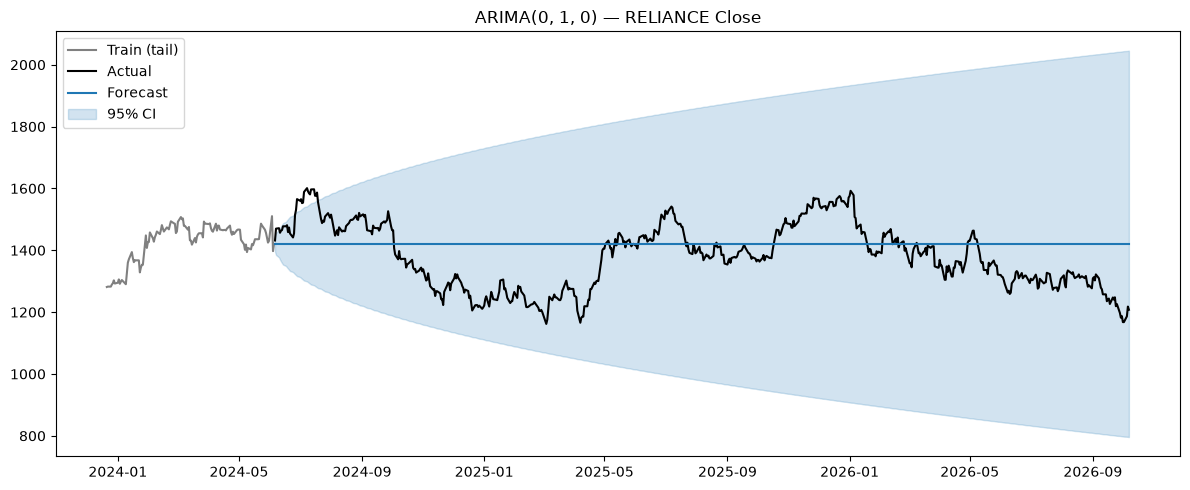

MAE : 92.973
RMSE: 111.642
MAPE: 6.98%


In [18]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.index[-120:], train.iloc[-120:], label="Train (tail)", color="gray")
ax.plot(test.index, test.values, label="Actual", color="black")
ax.plot(forecast.index, forecast.values, label="Forecast", color="C0")
ax.fill_between(
    conf_int.index,
    conf_int.iloc[:, 0],
    conf_int.iloc[:, 1],
    color="C0", alpha=0.2, label="95% CI",
)
ax.set_title(f"ARIMA{p, d, q} — RELIANCE Close")
ax.legend()
plt.tight_layout()
plt.show()

mae  = np.mean(np.abs(test.values - forecast.values))
rmse = np.sqrt(np.mean((test.values - forecast.values) ** 2))
mape = np.mean(np.abs((test.values - forecast.values) / test.values)) * 100

print(f"MAE : {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"MAPE: {mape:.2f}%")